<a href="https://colab.research.google.com/github/zainaBanglekar/CSL701-Roll_No_-CS03_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name :Zaina Mujaveed Banglekar

Batch :CS-1


Roll Number :CS03



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [4]:
import pandas as pd
import os

# Fallback: Download the dataset if it does not exist locally
if not os.path.exists("Mall_Customers.csv"):
    print("Downloading Mall_Customers.csv...")
    url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
    df = pd.read_csv(url)
    df.to_csv("Mall_Customers.csv", index=False)
else:
    df = pd.read_csv("Mall_Customers.csv")

display(df.head())
print("Dataset shape:", df.shape)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [5]:
from sklearn.preprocessing import StandardScaler

# Select features
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled features sample:")
print(X_scaled[:5])
print("\nScaled data shape:", X_scaled.shape)

Scaled features sample:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Scaled data shape: (200, 2)


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

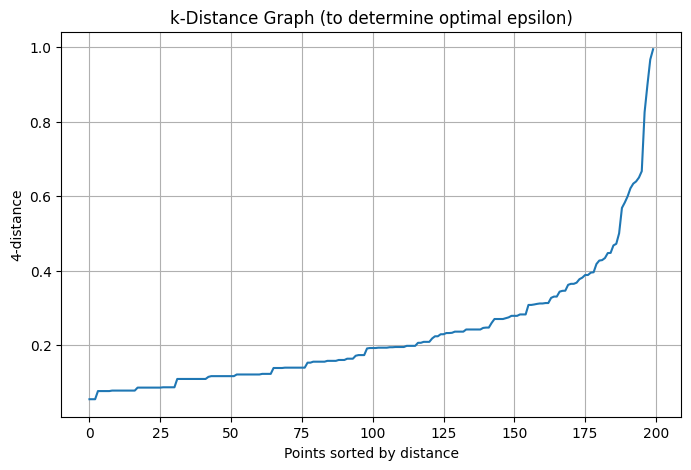

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# For 2D data, a common heuristic for MinPts (min_samples) is 4
min_samples = 4

# Fit Nearest Neighbors to find the distance to the k-th nearest neighbor
# k = min_samples (includes the point itself, so index min_samples-1 gives the k-th neighbor distance)
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort the distances of the k-th nearest neighbor
sorted_distances = np.sort(distances[:, min_samples - 1])

# Plot the sorted k-distances
plt.figure(figsize=(8, 5))
plt.plot(sorted_distances)
plt.title("k-Distance Graph (to determine optimal epsilon)")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-distance")
plt.grid(True)
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [7]:
from sklearn.cluster import DBSCAN

# Define optimal hyperparameters from k-distance elbow analysis
epsilon = 0.35
min_samples = 4

# Instantiate and fit DBSCAN
dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
dbscan.fit(X_scaled)

# Extract cluster labels
labels = dbscan.labels_

print("DBSCAN Clustering successfully fitted!")
print("Unique labels found:", np.unique(labels))

DBSCAN Clustering successfully fitted!
Unique labels found: [-1  0  1  2  3  4  5  6]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [8]:
from sklearn.metrics import silhouette_score

# Count the number of clusters (ignoring noise label -1)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_} (out of {len(X_scaled)} total points)")

# Calculate Silhouette Score (only on non-noise samples)
if n_clusters_ > 1:
    non_noise_mask = labels != -1
    score = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
    print(f"Silhouette Score (excluding noise): {score:.4f}")
else:
    print("Cannot calculate Silhouette Score: fewer than 2 clusters found.")

Estimated number of clusters: 7
Estimated number of noise points: 16 (out of 200 total points)
Silhouette Score (excluding noise): 0.5110


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [9]:
# Append the cluster labels back to the original dataframe
df['Cluster'] = labels

# Calculate mean statistics for each cluster
cluster_stats = df.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
}).rename(columns={'CustomerID': 'Customer Count'})

print("Cluster Statistics and Demographics:")
display(cluster_stats)

Cluster Statistics and Demographics:


,Customer Count,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
-1,16,33.750000,93.250000,65.812500
0,17,24.411765,25.235294,76.352941
1,12,48.750000,24.583333,9.583333
2,7,36.714286,22.428571,34.428571
3,89,42.797753,55.022472,48.325843
4,32,32.812500,80.500000,82.562500
5,23,41.217391,80.956522,12.782609
6,4,41.500000,101.000000,24.000000


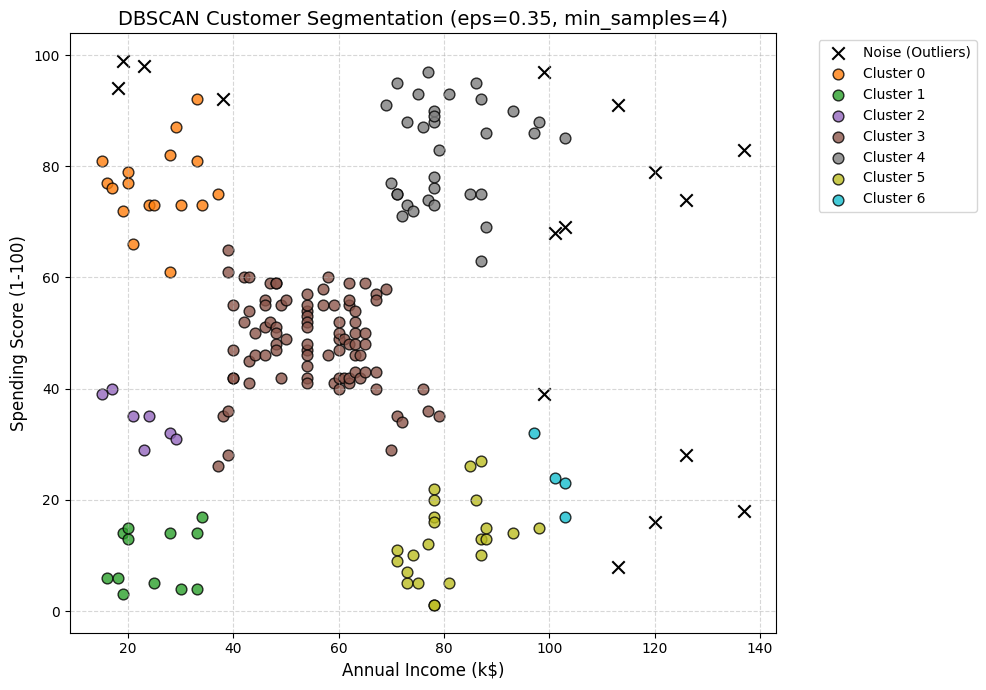

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Plot the clusters
plt.figure(figsize=(10, 7))

# Map each cluster label to a color (using the modern colormap API)
unique_clusters = np.unique(labels)
colors = plt.get_cmap('tab10', len(unique_clusters))

for i, cluster in enumerate(unique_clusters):
    # Filter data points belonging to this cluster
    mask = (labels == cluster)

    if cluster == -1:
        # Plot noise points as black cross markers
        plt.scatter(X[mask, 0], X[mask, 1], c='black', marker='x', s=80, label='Noise (Outliers)')
    else:
        # Plot dense clusters as circles
        plt.scatter(X[mask, 0], X[mask, 1], color=colors(i), s=60, label=f'Cluster {cluster}', edgecolors='black', alpha=0.8)

plt.title("DBSCAN Customer Segmentation (eps=0.35, min_samples=4)", fontsize=14)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.